# OpenCV滤波算法演示

本notebook演示了几种常见的OpenCV滤波算法，使用经典的Lena图片作为示例。

## 滤波算法简介

滤波是图像处理中的基础操作，主要用于：
- 降噪
- 平滑图像
- 去除图像中的不需要细节
- 为后续处理做准备

我们将演示以下几种滤波算法：
1. **均值滤波（Mean Blur）** - 简单平均，适用于高斯噪声
2. **高斯滤波（Gaussian Blur）** - 加权平均，效果更自然
3. **中值滤波（Median Blur）** - 适用于椒盐噪声
4. **双边滤波（Bilateral Filter）** - 保边去噪，保持边缘清晰


In [10]:
# 导入必要的库
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 设置matplotlib显示中文
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 设置图像显示大小
plt.rcParams['figure.figsize'] = (15, 10)


图像读取成功！
图像尺寸: (512, 512, 3)
图像类型: uint8


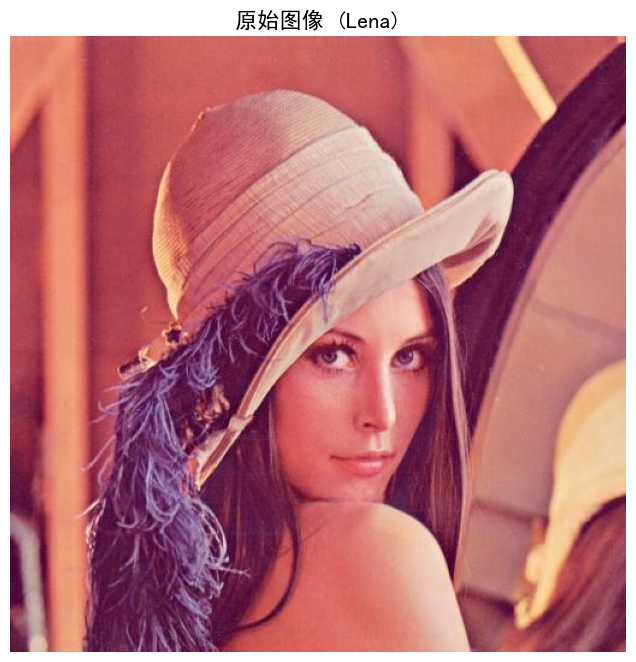

In [11]:
# 读取图像
img = cv2.imread('lena.jpg')

# 检查图像是否成功读取
if img is None:
    print("错误：无法读取图像文件 'lena.jpg'，请确保文件存在于当前目录")
else:
    print(f"图像读取成功！")
    print(f"图像尺寸: {img.shape}")
    print(f"图像类型: {img.dtype}")
    
    # 将BGR转换为RGB（matplotlib显示需要）
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # 显示原始图像
    plt.figure(figsize=(8, 8))
    plt.imshow(img_rgb)
    plt.title('原始图像 (Lena)', fontsize=16)
    plt.axis('off')
    plt.show()


## 1. 均值滤波（Mean Blur）

均值滤波是最简单的滤波方法，它用邻域内所有像素的平均值来替代中心像素值。

**原理**：
- 对每个像素，计算其邻域内所有像素的平均值
- 用这个平均值替代原像素值
- 核大小决定了平滑程度

**特点**：
- 简单快速
- 对高斯噪声有效
- 会模糊边缘


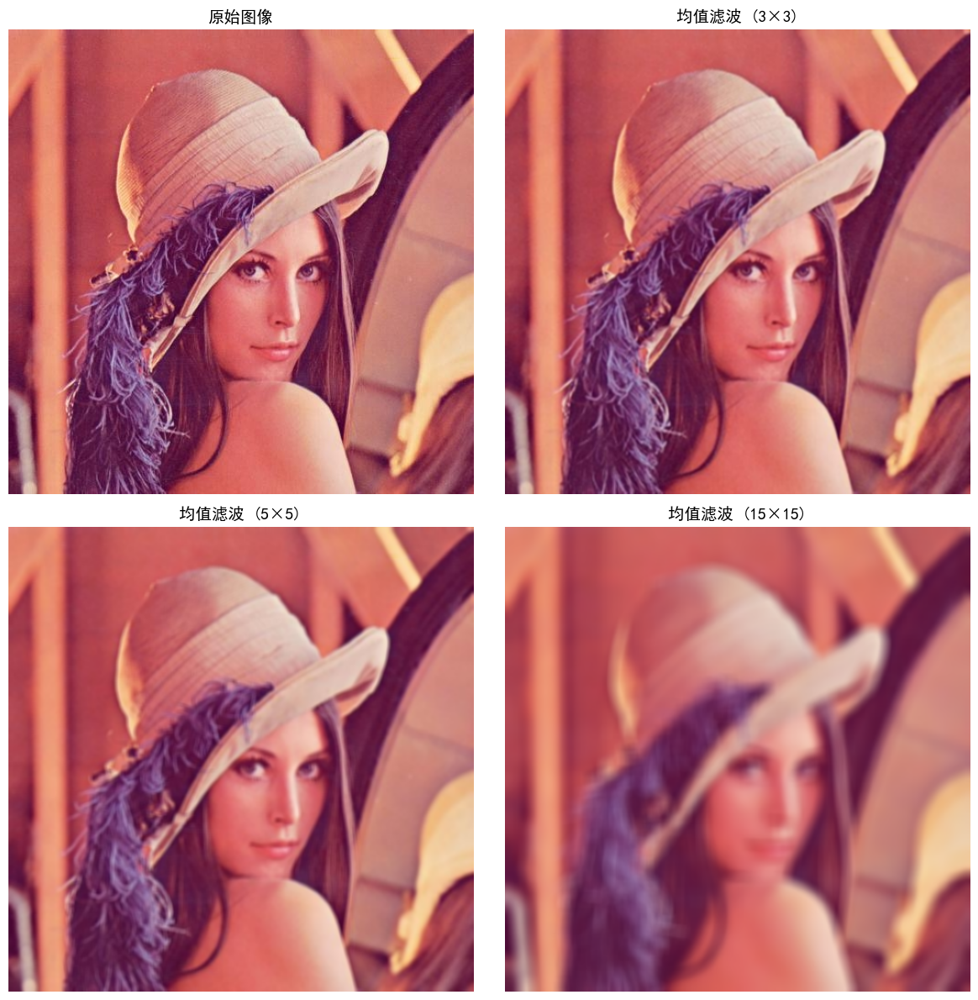

观察：随着核大小增加，图像变得越来越模糊


In [12]:
# 均值滤波演示
if img is not None:
    # 应用不同大小的均值滤波
    blur_3x3 = cv2.blur(img, (3, 3))
    blur_5x5 = cv2.blur(img, (5, 5))
    blur_15x15 = cv2.blur(img, (15, 15))
    
    # 转换为RGB格式
    blur_3x3_rgb = cv2.cvtColor(blur_3x3, cv2.COLOR_BGR2RGB)
    blur_5x5_rgb = cv2.cvtColor(blur_5x5, cv2.COLOR_BGR2RGB)
    blur_15x15_rgb = cv2.cvtColor(blur_15x15, cv2.COLOR_BGR2RGB)
    
    # 显示结果
    fig, axes = plt.subplots(2, 2, figsize=(12, 12))
    
    axes[0,0].imshow(img_rgb)
    axes[0,0].set_title('原始图像', fontsize=14)
    axes[0,0].axis('off')
    
    axes[0,1].imshow(blur_3x3_rgb)
    axes[0,1].set_title('均值滤波 (3×3)', fontsize=14)
    axes[0,1].axis('off')
    
    axes[1,0].imshow(blur_5x5_rgb)
    axes[1,0].set_title('均值滤波 (5×5)', fontsize=14)
    axes[1,0].axis('off')
    
    axes[1,1].imshow(blur_15x15_rgb)
    axes[1,1].set_title('均值滤波 (15×15)', fontsize=14)
    axes[1,1].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print("观察：随着核大小增加，图像变得越来越模糊")


## 2. 高斯滤波（Gaussian Blur）

高斯滤波使用高斯函数作为滤波核，给不同距离的像素分配不同的权重。

**原理**：
- 距离中心越近的像素权重越大
- 距离中心越远的像素权重越小
- 权重分布符合高斯分布

**参数**：
- `ksize`: 核大小（必须为奇数）
- `sigmaX`: X方向标准差
- `sigmaY`: Y方向标准差（可选）

**特点**：
- 效果比均值滤波更自然
- 保持图像的整体结构
- 广泛应用于图像预处理


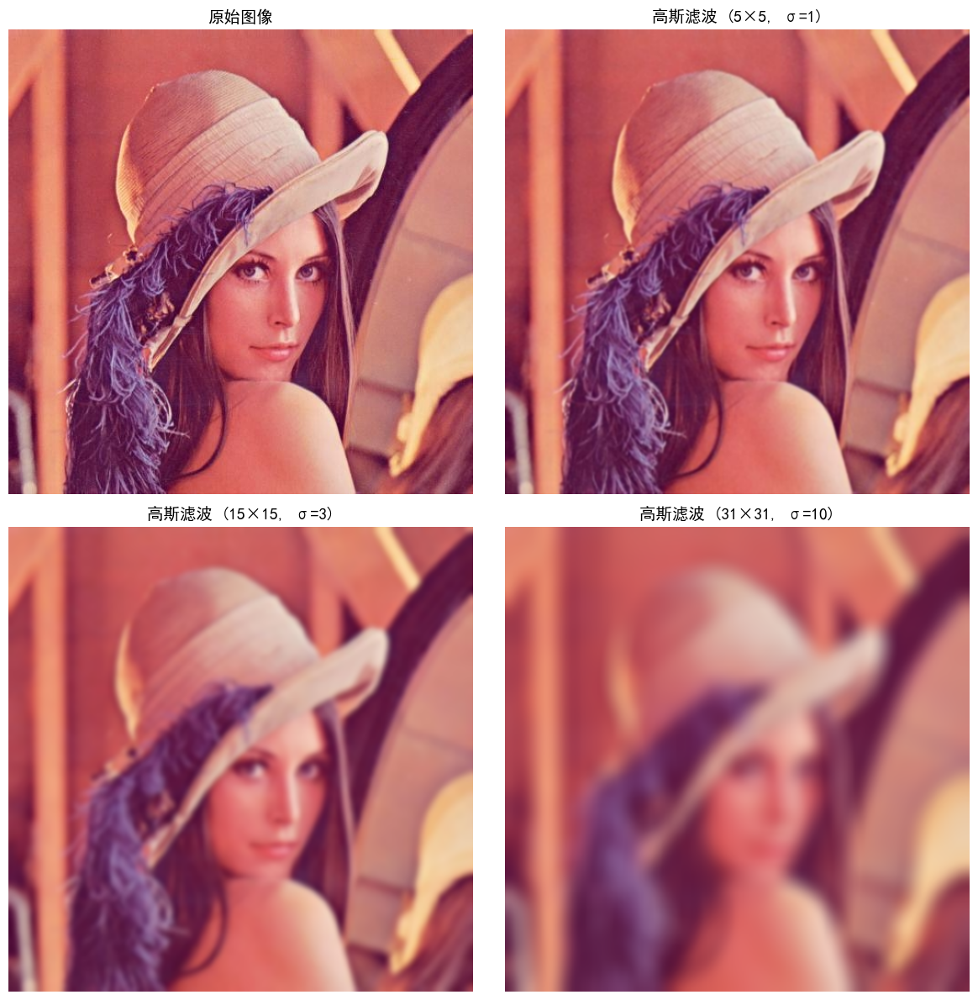

观察：高斯滤波的效果比均值滤波更加自然平滑


In [13]:
# 高斯滤波演示
if img is not None:
    # 应用不同参数的高斯滤波
    gaussian_small = cv2.GaussianBlur(img, (5, 5), 1)
    gaussian_medium = cv2.GaussianBlur(img, (15, 15), 3)
    gaussian_large = cv2.GaussianBlur(img, (31, 31), 10)
    
    # 转换为RGB格式
    gaussian_small_rgb = cv2.cvtColor(gaussian_small, cv2.COLOR_BGR2RGB)
    gaussian_medium_rgb = cv2.cvtColor(gaussian_medium, cv2.COLOR_BGR2RGB)
    gaussian_large_rgb = cv2.cvtColor(gaussian_large, cv2.COLOR_BGR2RGB)
    
    # 显示结果
    fig, axes = plt.subplots(2, 2, figsize=(12, 12))
    
    axes[0,0].imshow(img_rgb)
    axes[0,0].set_title('原始图像', fontsize=14)
    axes[0,0].axis('off')
    
    axes[0,1].imshow(gaussian_small_rgb)
    axes[0,1].set_title('高斯滤波 (5×5, σ=1)', fontsize=14)
    axes[0,1].axis('off')
    
    axes[1,0].imshow(gaussian_medium_rgb)
    axes[1,0].set_title('高斯滤波 (15×15, σ=3)', fontsize=14)
    axes[1,0].axis('off')
    
    axes[1,1].imshow(gaussian_large_rgb)
    axes[1,1].set_title('高斯滤波 (31×31, σ=10)', fontsize=14)
    axes[1,1].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print("观察：高斯滤波的效果比均值滤波更加自然平滑")


## 3. 中值滤波（Median Blur）

中值滤波用邻域内像素的中值来替代中心像素值，是一种非线性滤波方法。

**原理**：
- 对每个像素，获取其邻域内所有像素值
- 将这些值排序，取中间值（中位数）
- 用中位数替代原像素值

**特点**：
- 对椒盐噪声（黑白点噪声）非常有效
- 能够很好地保持边缘
- 不会产生新的像素值
- 只能使用奇数大小的核


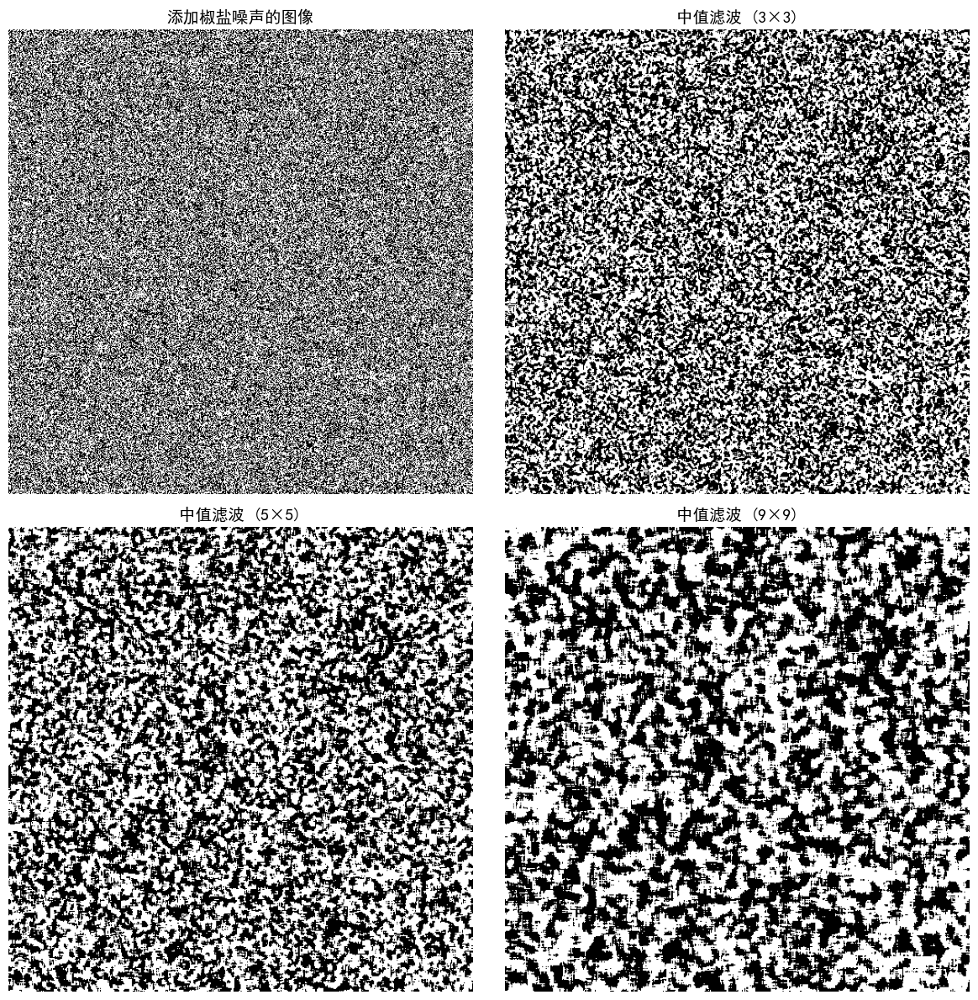

观察：中值滤波能够有效去除椒盐噪声，同时保持边缘清晰


In [14]:
# 中值滤波演示
if img is not None:
    # 首先给图像添加椒盐噪声，以便更好地展示中值滤波的效果
    img_noisy = img.copy()
    noise = np.random.randint(0, 2, size=img.shape[:2])
    img_noisy[noise == 0] = 0      # 椒噪声（黑点）
    img_noisy[noise == 1] = 255    # 盐噪声（白点）
    
    # 应用不同大小的中值滤波
    median_3 = cv2.medianBlur(img_noisy, 3)
    median_5 = cv2.medianBlur(img_noisy, 5)
    median_9 = cv2.medianBlur(img_noisy, 9)
    
    # 转换为RGB格式
    img_noisy_rgb = cv2.cvtColor(img_noisy, cv2.COLOR_BGR2RGB)
    median_3_rgb = cv2.cvtColor(median_3, cv2.COLOR_BGR2RGB)
    median_5_rgb = cv2.cvtColor(median_5, cv2.COLOR_BGR2RGB)
    median_9_rgb = cv2.cvtColor(median_9, cv2.COLOR_BGR2RGB)
    
    # 显示结果
    fig, axes = plt.subplots(2, 2, figsize=(12, 12))
    
    axes[0,0].imshow(img_noisy_rgb)
    axes[0,0].set_title('添加椒盐噪声的图像', fontsize=14)
    axes[0,0].axis('off')
    
    axes[0,1].imshow(median_3_rgb)
    axes[0,1].set_title('中值滤波 (3×3)', fontsize=14)
    axes[0,1].axis('off')
    
    axes[1,0].imshow(median_5_rgb)
    axes[1,0].set_title('中值滤波 (5×5)', fontsize=14)
    axes[1,0].axis('off')
    
    axes[1,1].imshow(median_9_rgb)
    axes[1,1].set_title('中值滤波 (9×9)', fontsize=14)
    axes[1,1].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print("观察：中值滤波能够有效去除椒盐噪声，同时保持边缘清晰")


## 4. 双边滤波（Bilateral Filter）

双边滤波是一种非线性滤波方法，能够在去噪的同时保持边缘清晰。

**原理**：
- 同时考虑空间距离和像素值差异
- 空间距离近且像素值相似的点权重大
- 空间距离远或像素值差异大的点权重小

**参数**：
- `d`: 像素邻域直径
- `sigmaColor`: 颜色空间的标准差
- `sigmaSpace`: 坐标空间的标准差

**特点**：
- 保边去噪效果优秀
- 计算复杂度较高
- 广泛应用于图像美化和预处理


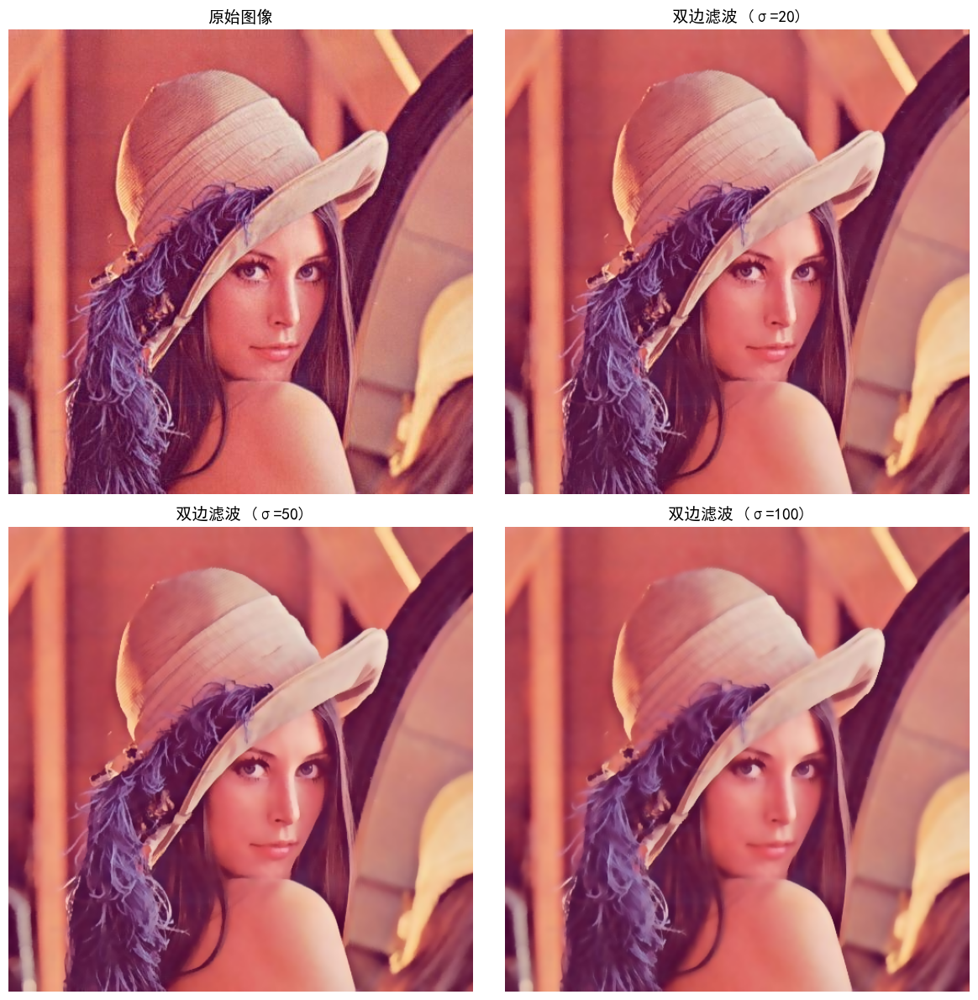

观察：双边滤波能够平滑图像的同时保持边缘清晰


In [15]:
# 双边滤波演示
if img is not None:
    # 应用不同参数的双边滤波
    bilateral_light = cv2.bilateralFilter(img, 9, 20, 20)   # 轻度滤波
    bilateral_medium = cv2.bilateralFilter(img, 9, 50, 50)  # 中度滤波
    bilateral_strong = cv2.bilateralFilter(img, 9, 100, 100) # 强度滤波
    
    # 转换为RGB格式
    bilateral_light_rgb = cv2.cvtColor(bilateral_light, cv2.COLOR_BGR2RGB)
    bilateral_medium_rgb = cv2.cvtColor(bilateral_medium, cv2.COLOR_BGR2RGB)
    bilateral_strong_rgb = cv2.cvtColor(bilateral_strong, cv2.COLOR_BGR2RGB)
    
    # 显示结果
    fig, axes = plt.subplots(2, 2, figsize=(12, 12))
    
    axes[0,0].imshow(img_rgb)
    axes[0,0].set_title('原始图像', fontsize=14)
    axes[0,0].axis('off')
    
    axes[0,1].imshow(bilateral_light_rgb)
    axes[0,1].set_title('双边滤波 (σ=20)', fontsize=14)
    axes[0,1].axis('off')
    
    axes[1,0].imshow(bilateral_medium_rgb)
    axes[1,0].set_title('双边滤波 (σ=50)', fontsize=14)
    axes[1,0].axis('off')
    
    axes[1,1].imshow(bilateral_strong_rgb)
    axes[1,1].set_title('双边滤波 (σ=100)', fontsize=14)
    axes[1,1].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print("观察：双边滤波能够平滑图像的同时保持边缘清晰")


## 5. 滤波算法对比

让我们将四种滤波算法应用到同一张图像上，直观地比较它们的效果。


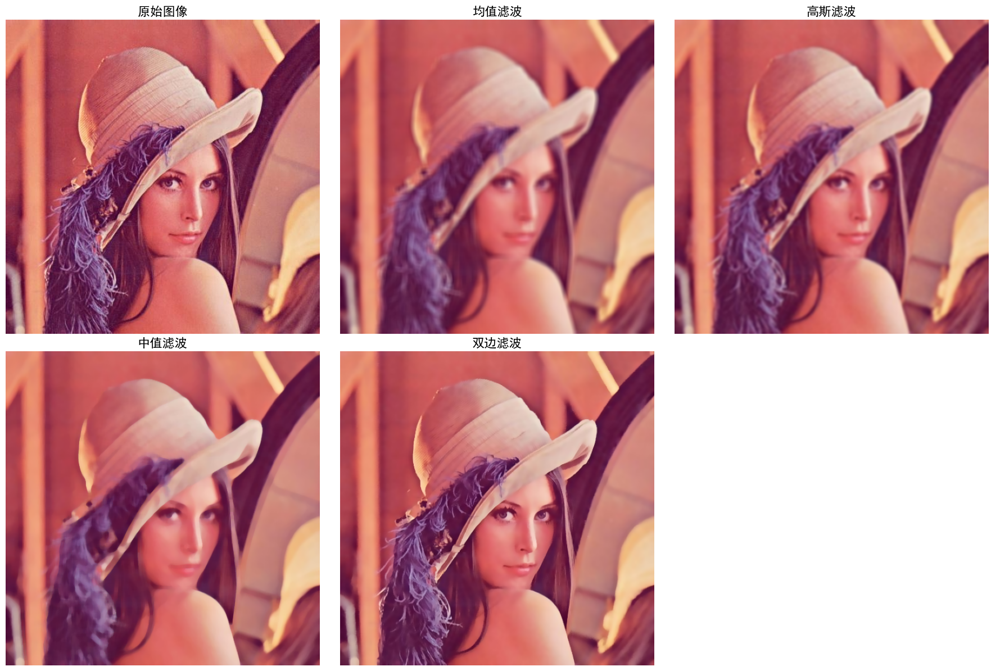

\n各种滤波算法的特点总结：
• 均值滤波：最简单，会模糊边缘
• 高斯滤波：效果自然，广泛应用
• 中值滤波：去除椒盐噪声效果好，保持边缘
• 双边滤波：保边去噪，效果最佳但计算量大


In [16]:
# 滤波算法对比
if img is not None:
    # 应用四种滤波算法（使用相似的参数）
    mean_blur = cv2.blur(img, (9, 9))
    gaussian_blur = cv2.GaussianBlur(img, (9, 9), 2)
    median_blur = cv2.medianBlur(img, 9)
    bilateral_blur = cv2.bilateralFilter(img, 9, 50, 50)
    
    # 转换为RGB格式
    mean_blur_rgb = cv2.cvtColor(mean_blur, cv2.COLOR_BGR2RGB)
    gaussian_blur_rgb = cv2.cvtColor(gaussian_blur, cv2.COLOR_BGR2RGB)
    median_blur_rgb = cv2.cvtColor(median_blur, cv2.COLOR_BGR2RGB)
    bilateral_blur_rgb = cv2.cvtColor(bilateral_blur, cv2.COLOR_BGR2RGB)
    
    # 创建对比图
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    
    # 第一行
    axes[0,0].imshow(img_rgb)
    axes[0,0].set_title('原始图像', fontsize=16, fontweight='bold')
    axes[0,0].axis('off')
    
    axes[0,1].imshow(mean_blur_rgb)
    axes[0,1].set_title('均值滤波', fontsize=16)
    axes[0,1].axis('off')
    
    axes[0,2].imshow(gaussian_blur_rgb)
    axes[0,2].set_title('高斯滤波', fontsize=16)
    axes[0,2].axis('off')
    
    # 第二行
    axes[1,0].imshow(median_blur_rgb)
    axes[1,0].set_title('中值滤波', fontsize=16)
    axes[1,0].axis('off')
    
    axes[1,1].imshow(bilateral_blur_rgb)
    axes[1,1].set_title('双边滤波', fontsize=16)
    axes[1,1].axis('off')
    
    # 隐藏最后一个子图
    axes[1,2].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print("\\n各种滤波算法的特点总结：")
    print("• 均值滤波：最简单，会模糊边缘")
    print("• 高斯滤波：效果自然，广泛应用")
    print("• 中值滤波：去除椒盐噪声效果好，保持边缘")
    print("• 双边滤波：保边去噪，效果最佳但计算量大")


## 总结

通过本次演示，我们学习了四种常见的OpenCV滤波算法：

### 算法选择指南

| 滤波算法 | 适用场景 | 优点 | 缺点 |
|---------|---------|------|------|
| 均值滤波 | 简单降噪、快速处理 | 计算简单、速度快 | 会模糊边缘 |
| 高斯滤波 | 一般图像预处理 | 效果自然、应用广泛 | 仍会模糊边缘 |
| 中值滤波 | 椒盐噪声去除 | 保持边缘、去除脉冲噪声 | 对高斯噪声效果一般 |
| 双边滤波 | 高质量图像处理 | 保边去噪效果最佳 | 计算复杂、速度慢 |

### 课堂要点

1. **滤波的本质**：用邻域信息替代原像素值
2. **核大小的影响**：核越大，平滑效果越强
3. **线性vs非线性**：均值和高斯是线性的，中值和双边是非线性的
4. **实际应用**：根据具体需求选择合适的滤波算法

### 下一步学习

- 边缘检测算法（Canny、Sobel等）
- 形态学操作（开运算、闭运算等）
- 特征检测与匹配
- 图像分割技术
